<a href="https://colab.research.google.com/github/aurelphy/-4/blob/main/%D0%9B%D0%A0_4_%D0%92%D0%B8%D0%B7%D1%83%D0%B0%D0%BB%D0%B8%D0%B7%D0%B0%D1%86%D0%B8%D1%8F_%D0%BF%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D0%BA%D0%B0_Telco.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практикум. Визуализация данных в Python: matplotlib, seaborn, plotly

«Анализ данных»

Это практический ноутбук о визуализации данных. Он воспроизводит демонстрацию: один и тот же график строится последовательно в трёх
библиотеках, чтобы увидеть, чем они отличаются на практике.


В лекции разбирались пять видов сравнения метрик (покомпонентное, позиционное, временное,
частотное, корреляционное). Здесь для каждого из них подбирается подходящий график и
строится на реальных данных.

| Библиотека | Плюсы | Когда стоит применить |
|---|---|---|
| `matplotlib` | полный контроль над каждым элементом рисунка | публикации, точная подгонка оформления |
| `seaborn` | статистические графики одной строкой, разбивки через `hue` | разведочный анализ (EDA) |
| `plotly.express` | интерактивность: зум, подсказки, легенда-переключатель | демонстрации, отчёты, работа с плотными данными |

Синтаксис у всех трёх похож (данные, оси, разбивка по категории), поэтому переход
между библиотеками обычно занимает минуты, а не дни.

### Данные

Открытый набор **Telco Customer Churn** (IBM; публикация на Kaggle — `blastchar/telco-customer-churn`).
7043 договора, 21 поле. Единица наблюдения — клиент телеком-оператора (`customerID`),
целевая переменная — отток (`Churn`). Поля: демографические признаки (`gender`, `SeniorCitizen`,
`Partner`, `Dependents`), подключённые услуги (`InternetService`, `StreamingTV`, ...),
условия договора (`Contract`, `PaymentMethod`) и суммы платежей (`MonthlyCharges`, `TotalCharges`).

Ссылки на скачивание:

* [IBM, прямая ссылка на CSV](https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv)
* [Зеркало на Hugging Face](https://huggingface.co/datasets/mnemoraorg/telco-churn-7k)
* [Карточка набора на Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

### Как запускать

Ноутбук рассчитан на чтение сверху вниз и работает в Google Colab без настройки:
файл данных скачивается из сети первой же ячейкой. Локально нужны `pandas`,
`matplotlib`, `seaborn`, `plotly` — ячейка импортов при необходимости доустановит их.

## 0. Импорты и настройки оформления


`sns.set_theme` меняет стиль и для чистого `matplotlib` тоже — seaborn работает
поверх него, а не вместо него.

In [69]:
import subprocess
import sys

# В Colab всё уже установлено; строка ниже нужна для локального запуска «с нуля».
for module, package in [("pandas", "pandas"), ("matplotlib", "matplotlib"),
                        ("seaborn", "seaborn"), ("plotly", "plotly")]:
    try:
        __import__(module)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import plotly
import plotly.express as px
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    display = print

%matplotlib inline

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["figure.dpi"] = 110

pd.set_option("display.max_columns", 24)
pd.set_option("display.width", 120)

# Единая палитра для оттока во всём ноутбуке: отток выделен акцентным цветом.
CHURN_COLORS = {"No": "#4C72B0", "Yes": "#C44E52"}

print("pandas ", pd.__version__)
print("seaborn", sns.__version__)
print("plotly ", plotly.__version__)

pandas  2.2.3
seaborn 0.13.2
plotly  5.24.1


## 1. Загрузка данных

Данные читаются напрямую по URL. Если сети нет или зеркало недоступно, ноутбук
ищет файл рядом с собой — поэтому в аудитории он работает и без интернета,
если CSV заранее положен в папку с ноутбуком или в `data/`.

In [70]:
CSV_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
CSV_MIRROR = "https://huggingface.co/datasets/mnemoraorg/telco-churn-7k/resolve/main/telco_churn_7k.csv"
LOCAL_CANDIDATES = [
    Path("WA_Fn-UseC_-Telco-Customer-Churn.csv"),
    Path("Telco-Customer-Churn.csv"),
    Path("data") / "WA_Fn-UseC_-Telco-Customer-Churn.csv",
    Path("data") / "Telco-Customer-Churn.csv",
    Path("/content") / "WA_Fn-UseC_-Telco-Customer-Churn.csv",
]

df = None
source = None

for url in [CSV_URL, CSV_MIRROR]:
    try:
        df = pd.read_csv(url)
        source = url
        break
    except Exception as err:
        print(f"Недоступно: {url} ({type(err).__name__})")

if df is None:
    for path in LOCAL_CANDIDATES:
        if path.exists():
            df = pd.read_csv(path)
            source = str(path)
            break

if df is None:
    raise FileNotFoundError(
        "Датасет не найден. Скачайте WA_Fn-UseC_-Telco-Customer-Churn.csv "
        "(Kaggle: blastchar/telco-customer-churn) и положите рядом с ноутбуком."
    )

print("Источник:", source)
print("Строк и столбцов:", df.shape)

Источник: https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv
Строк и столбцов: (7043, 21)


Перед первым графиком всегда полезно посмотреть на таблицу глазами: `head()` показывает,
что вообще лежит в полях, `info()` — типы и пропуски. Это тот самый шаг, без которого
график может оказаться технически верным, но бессмысленным.

In [71]:
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 2. Приведение типов: `TotalCharges`

`info()` показывает, что `TotalCharges` прочитан как строка (`object` в pandas 2.x, `str`
в pandas 3.x), хотя это сумма платежей за весь срок обслуживания. Причина — в файле есть
строки с пробелом вместо числа.
Пока столбец текстовый, по нему нельзя ни посчитать среднее, ни построить гистограмму.

`pd.to_numeric(..., errors="coerce")` превращает столбец в числовой, а всё, что не разобралось,
записывает как пропуск `NaN`. Дальше видно, что это за строки: у них `tenure = 0` —
клиенты подключились в текущем месяце, платежей за весь срок у них ещё нет.
Это не грязь в данных, а осмысленная ситуация; удалять такие строки вслепую не нужно.

In [73]:
print("Тип до приведения:", df["TotalCharges"].dtype)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Тип после приведения:", df["TotalCharges"].dtype)
print("Пропусков появилось:", int(df["TotalCharges"].isna().sum()))

display(df.loc[df["TotalCharges"].isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

Тип до приведения: object
Тип после приведения: float64
Пропусков появилось: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


Второй служебный шаг — числовой флаг оттока. Текстовые `"Yes"` / `"No"` удобны в легенде
графика, но по флагу `0/1` среднее значение сразу равно доле оттока. Этим приёмом
пользуются все графики ниже, где по оси Y стоит «доля ушедших».

In [74]:
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

print("Общая доля оттока:", round(df["ChurnFlag"].mean(), 3))
display(df[["tenure", "MonthlyCharges", "TotalCharges", "ChurnFlag"]].describe().round(2))

Общая доля оттока: 0.265


,tenure,MonthlyCharges,TotalCharges,ChurnFlag
count,7043.00,7043.00,7032.00,7043.00
mean,32.37,64.76,2283.30,0.27
std,24.56,30.09,2266.77,0.44
min,0.00,18.25,18.80,0.00
25%,9.00,35.50,401.45,0.00
50%,29.00,70.35,1397.48,0.00
75%,55.00,89.85,3794.74,1.00
max,72.00,118.75,8684.80,1.00


## 3. Частотное сравнение: одна гистограмма в трёх библиотеках

Гистограмма отвечает на вопрос «сколько наблюдений попало в интервал» — это частотное
сравнение из лекции. Возьмём месячный платёж `MonthlyCharges` и построим по нему
распределение три раза подряд, ничего не меняя в данных. Различия будут только в коде и
в возможностях графика.

### 3.1. matplotlib

Самый низкий уровень: рисунок (`fig`) и система координат (`ax`) создаются вручную,
заголовок и подписи осей задаются отдельными вызовами.

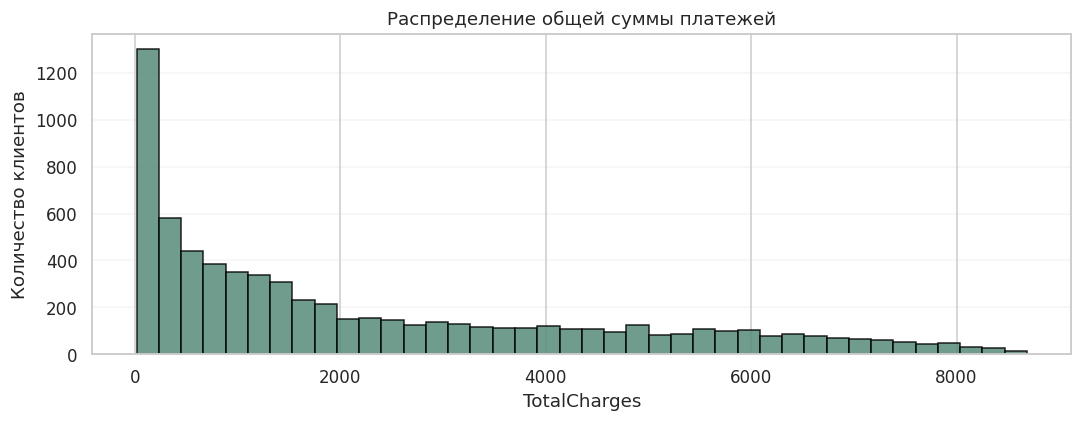

In [75]:

charges = df["TotalCharges"].dropna()

fig, ax = plt.subplots(figsize=(10, 4))

ax.hist(
    charges,
    bins=40,
    color="#568B78",
    edgecolor="black",
    alpha=0.85
)

ax.set_title("Распределение общей суммы платежей")
ax.set_xlabel("TotalCharges")
ax.set_ylabel("Количество клиентов")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

На графике видно две особенности распределения: плотный пик в районе 20 \$ — клиенты
с минимальным тарифом без интернета — и широкая «плита» от 70 до 105 \$. Это уже
содержательный вывод: аудитория оператора распадается минимум на две группы, и считать
по ней одно «среднее» значение было бы ошибкой.

### 3.2. seaborn

Тот же график одной строкой. Дополнительно попросим сглаженную кривую плотности
(`kde=True`) — в лекции это был приём «распределение линией по интервалам вместо столбцов».

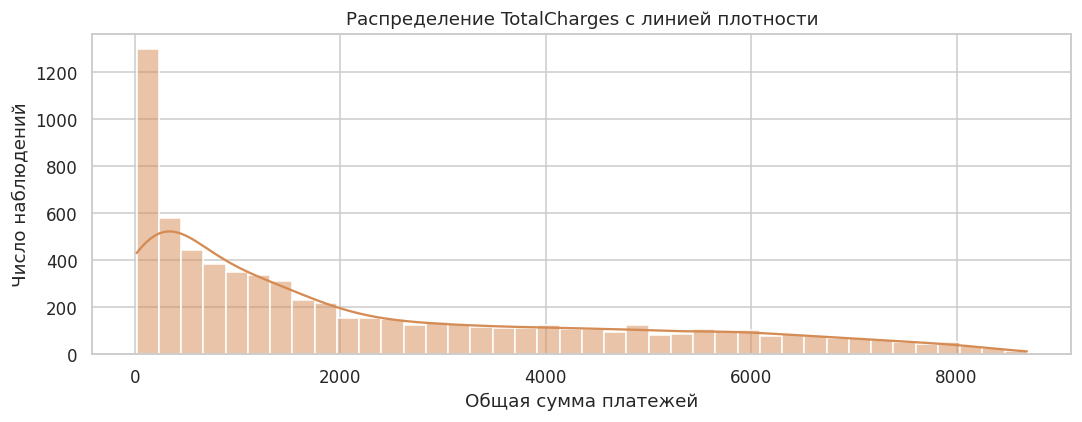

In [76]:
fig, ax = plt.subplots(figsize=(10, 4))

sns.histplot(
    data=df.dropna(subset=["TotalCharges"]),
    x="TotalCharges",
    bins=40,
    kde=True,
    color="#D58B54",
    ax=ax
)

ax.set_title("Распределение TotalCharges с линией плотности")
ax.set_xlabel("Общая сумма платежей")
ax.set_ylabel("Число наблюдений")

plt.tight_layout()
plt.show()

Главное преимущество seaborn проявляется, когда нужна разбивка по категории: достаточно
добавить `hue`, и библиотека сама разделит данные, подберёт цвета и построит легенду.
Сравним распределение платежа у ушедших и оставшихся клиентов.

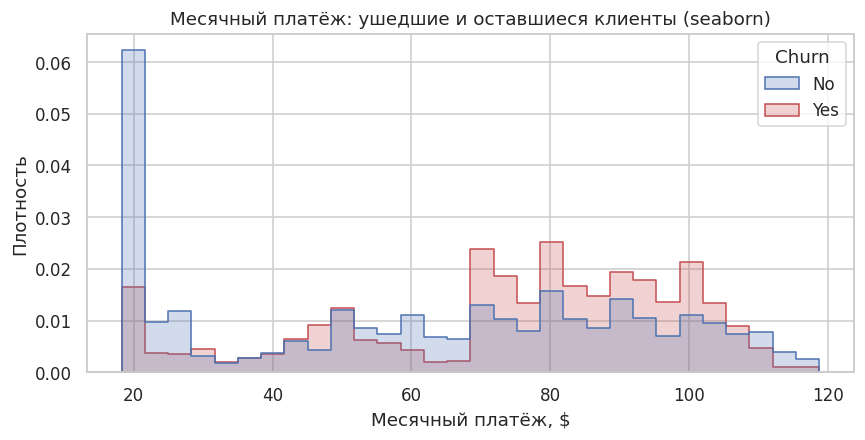

In [77]:
ax = sns.histplot(
    data=df,
    x="MonthlyCharges",
    hue="Churn",
    bins=30,
    element="step",
    stat="density",
    common_norm=False,
    palette=CHURN_COLORS,
)

ax.set_title("Месячный платёж: ушедшие и оставшиеся клиенты (seaborn)")
ax.set_xlabel("Месячный платёж, $")
ax.set_ylabel("Плотность")

plt.show()

`stat="density"` и `common_norm=False` нормируют каждую группу отдельно. Без этого
группа «No» просто выше в три раза (её больше в выборке), и формы распределений
сравнить невозможно. После нормировки видно: отток сдвинут в область дорогих тарифов.

### 3.3. plotly

Тот же график, но интерактивный: можно приблизить участок, навести курсор на столбец
и увидеть точные значения, выключить группу кликом по легенде. На плотных данных это
экономит много времени по сравнению со статичной картинкой.

In [78]:
!pip install --upgrade nbformat


In [79]:
charges_data = df.dropna(subset=["TotalCharges"])

fig = px.histogram(
    charges_data,
    x="TotalCharges",
    nbins=40,
    color_discrete_sequence=["#8064A2"],
    title="Интерактивное распределение общей суммы платежей",
    labels={
        "TotalCharges": "Общая сумма платежей, $",
        "count": "Количество клиентов"
    }
)

fig.update_layout(
    width=950,
    height=450,
    bargap=0.08,
    template="plotly_white"
)

fig.show()

> **Если график не отображается.** В Colab и современном Jupyter plotly работает сразу.
> В отдельных сборках Jupyter нужен пакет `nbformat` (`pip install nbformat`); при экспорте
> в статичный HTML или PDF интерактивные графики заменяются картинками только при
> установленном `kaleido`.

## 4. Покомпонентное сравнение: способ оплаты

Вопрос: как распределены клиенты по способу оплаты и связан ли способ оплаты с оттоком.
Это покомпонентное сравнение — доли категорий внутри одного целого. В лекции для него
предлагалась круговая диаграмма, но строго при 4–5 категориях и без мелких долей.
Здесь категорий ровно четыре, и всё же столбчатая диаграмма читается точнее: длины
столбцов человек сравнивает надёжнее, чем углы секторов.

Начинаем не с графика, а с чисел — `value_counts()`.

In [80]:
payment_counts = df["PaymentMethod"].value_counts()
payment_share = df["PaymentMethod"].value_counts(normalize=True).mul(100).round(1)

summary = pd.DataFrame({"Клиентов": payment_counts, "Доля, %": payment_share})
summary["Доля оттока, %"] = (
    df.groupby("PaymentMethod")["ChurnFlag"].mean().mul(100).round(1)
)

display(summary)

,Клиентов,"Доля, %","Доля оттока, %"
PaymentMethod,,,
Electronic check,2365,33.6,45.3
Mailed check,1612,22.9,19.1
Bank transfer (automatic),1544,21.9,16.7
Credit card (automatic),1522,21.6,15.2


Числа уже дают ответ: у оплаты электронным чеком (`Electronic check`) доля оттока около 45 %,
тогда как у автоплатежей с карты и со счёта — 15–17 %. График нужен, чтобы этот контраст
было видно с одного взгляда.

### 4.1. seaborn: countplot

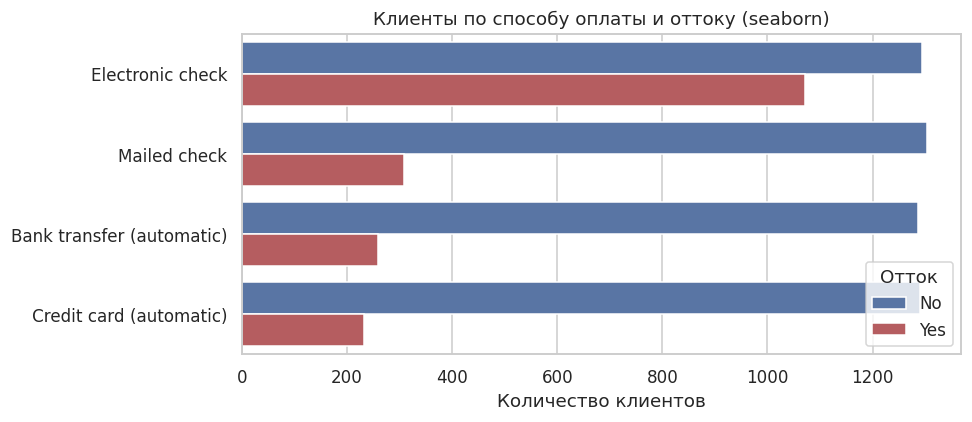

In [81]:
fig, ax = plt.subplots(figsize=(9, 4))

sns.countplot(
    data=df,
    y="PaymentMethod",
    hue="Churn",
    order=payment_counts.index,
    palette=CHURN_COLORS,
    ax=ax,
)

ax.set_title("Клиенты по способу оплаты и оттоку (seaborn)")
ax.set_xlabel("Количество клиентов")
ax.set_ylabel("")
ax.legend(title="Отток")

plt.tight_layout()
plt.show()

Категории отложены по вертикальной оси: длинные названия способов оплаты так читаются
без наклона подписей. Порядок задан явно через `order` — по убыванию численности,
иначе seaborn расставил бы категории в случайном для читателя порядке.

### 4.2. plotly: тот же график плюс доля оттока

Столбцы в режиме `group` показывают абсолютные количества, а вторая диаграмма — уже
не количество, а долю оттока внутри каждой категории. Это разные вопросы, и смешивать
их на одной оси нельзя: у них разные единицы измерения.

In [82]:
fig = px.histogram(
    df,
    y="PaymentMethod",
    color="Churn",
    barmode="group",
    color_discrete_map=CHURN_COLORS,
    category_orders={"PaymentMethod": list(payment_counts.index)},
    title="Клиенты по способу оплаты (plotly)",
    labels={"PaymentMethod": "Способ оплаты", "Churn": "Отток"},
)

fig.update_layout(xaxis_title="Количество клиентов", width=900, height=420, legend_title_text="Отток")
fig.show()

In [83]:
churn_by_payment = (
    df.groupby("PaymentMethod", as_index=False)["ChurnFlag"]
    .mean()
    .assign(ChurnRate=lambda t: (t["ChurnFlag"] * 100).round(1))
    .sort_values("ChurnRate")
)

fig = px.bar(
    churn_by_payment,
    x="ChurnRate",
    y="PaymentMethod",
    orientation="h",
    text="ChurnRate",
    range_x=[0, 50],
    title="Доля оттока по способу оплаты, %",
    labels={"ChurnRate": "Доля оттока, %", "PaymentMethod": "Способ оплаты"},
)

fig.update_traces(marker_color="#C44E52", texttemplate="%{text}%", textposition="outside")
fig.update_layout(width=900, height=380)
fig.show()

Ось X начинается с нуля (`range_x=[0, 50]`). Это прямое требование из лекции: обрезанная
ось визуально раздувает различия и вводит читателя в заблуждение. Здесь разрыв между
категориями и так трёхкратный — приукрашивать нечего.

## 5. Временное сравнение: динамика по сроку обслуживания

`tenure` — сколько месяцев клиент с оператором. Сгруппируем по этому полю и посмотрим,
как с ростом срока меняется доля оттока. Формально это не календарное время, а «возраст»
клиента, поэтому график читается как кривая созревания метрики — тот же принцип, что
у винтажного (когортного) анализа из лекции.

In [84]:
tenure_stats = (
    df.groupby("tenure")
    .agg(
        clients=("customerID", "count"),
        churn_rate=("ChurnFlag", "mean"),
        avg_monthly=("MonthlyCharges", "mean"),
    )
    .reset_index()
)

tenure_stats["churn_rate"] = (tenure_stats["churn_rate"] * 100).round(1)
tenure_stats["avg_monthly"] = tenure_stats["avg_monthly"].round(1)

display(tenure_stats.head())

,tenure,clients,churn_rate,avg_monthly
0,0,11,0.0,41.4
1,1,613,62.0,50.5
2,2,238,51.7,57.2
3,3,200,47.0,58.0
4,4,176,47.2,57.4


In [85]:

maturity_data = (
    df.groupby(["tenure", "Contract"])
      .agg(
          amount=("customerID", "count"),
          churn=("ChurnFlag", "mean")
      )
      .reset_index()
)

maturity_data["churn"] = maturity_data["churn"] * 100

fig = px.line(
    maturity_data,
    x="tenure",
    y="churn",
    color="Contract",
    markers=True,
    color_discrete_sequence=["#E76F51", "#457B9D", "#2A9D8F"],
    title="Изменение оттока в зависимости от срока договора",
    labels={
        "tenure": "Срок обслуживания, месяцев",
        "churn": "Доля оттока, %",
        "Contract": "Тип договора",
        "amount": "Количество клиентов"
    },
    hover_data=["amount"]
)

fig.update_layout(
    width=1000,
    height=500,
    yaxis_range=[0, 100],
    template="plotly_white"
)

fig.show()

Кривая падает резко на первых месяцах и дальше снижается плавно: среди клиентов
с одним месяцем обслуживания ушли 62 %, к шестому месяцу — около 36 %, к двум годам —
примерно 25 %, и только на сроках от пяти лет доля опускается до единиц процентов.
Основной риск оттока сосредоточен в самом начале жизни клиента — но он не исчезает
полностью и потом.

Один график редко бывает достаточным. Добавим к доле оттока численность клиентов
в каждой точке — чтобы видеть, на каком объёме данных посчитана каждая доля.
Совмещать их на одной оси нельзя (проценты и штуки — разные величины), поэтому
используем приём из лекции: два графика с общей осью X.

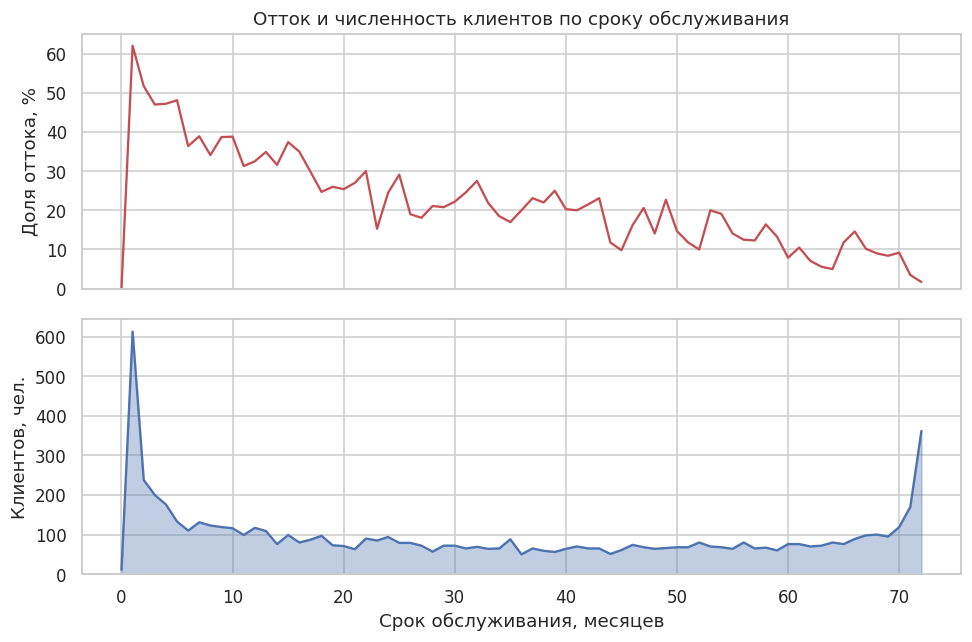

In [86]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

top.plot(tenure_stats["tenure"], tenure_stats["churn_rate"], color="#C44E52")
top.set_ylabel("Доля оттока, %")
top.set_ylim(0, 65)
top.set_title("Отток и численность клиентов по сроку обслуживания")

bottom.fill_between(tenure_stats["tenure"], tenure_stats["clients"], color="#4C72B0", alpha=0.35)
bottom.plot(tenure_stats["tenure"], tenure_stats["clients"], color="#4C72B0")
bottom.set_ylabel("Клиентов, чел.")
bottom.set_xlabel("Срок обслуживания, месяцев")
bottom.set_ylim(0, None)

plt.tight_layout()
plt.show()

Нижняя панель объясняет форму верхней: клиентов с очень маленьким и очень большим
сроком в выборке больше всего (U-образное распределение), а в середине наблюдений мало,
поэтому кривая оттока там заметно «дрожит». Без второй панели эти колебания можно
было бы принять за содержательный эффект.

## 6. Корреляционное сравнение: pairplot и диаграмма рассеяния

Корреляционное сравнение отвечает на вопрос «связаны ли две переменные». Базовый
инструмент — диаграмма рассеяния. У нас три числовых признака (`tenure`, `MonthlyCharges`,
`TotalCharges`), и seaborn умеет строить сразу все парные комбинации: `pairplot`.
На диагонали — распределения, вне диагонали — рассеяния, цвет — отток.

`corner=True` оставляет только нижний треугольник: верхний дублирует нижний зеркально
и лишь отвлекает. Ячейка считается несколько секунд — строится девять графиков.

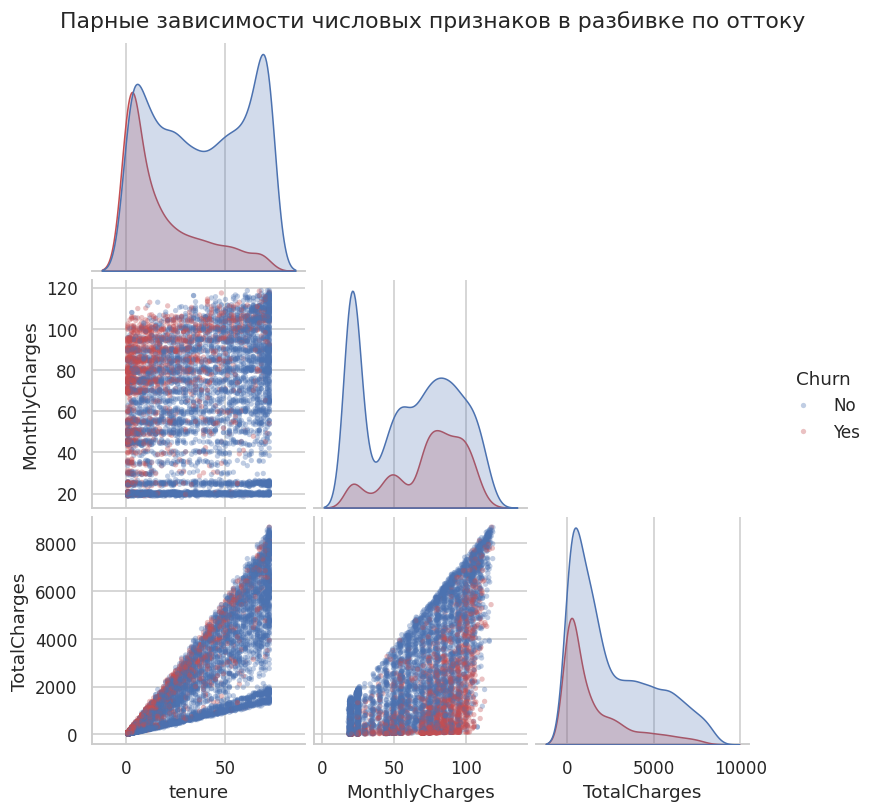

In [87]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

grid = sns.pairplot(
    df[numeric_cols + ["Churn"]].dropna(),
    hue="Churn",
    corner=True,
    palette=CHURN_COLORS,
    plot_kws={"alpha": 0.35, "s": 12, "edgecolor": "none"},
    height=2.4,
)

grid.figure.suptitle("Парные зависимости числовых признаков в разбивке по оттоку", y=1.02)
plt.show()

Что читается на этой сетке:

* `tenure` и `TotalCharges` почти линейно связаны — и это ожидаемо: общая сумма
  платежей есть примерно месячный платёж, умноженный на число месяцев. Наклон «веера»
  как раз задаётся тарифом;
* красные точки (отток) сосредоточены в левой части по `tenure` и в верхней по
  `MonthlyCharges` — ушедшие клиенты это в основном новички на дорогих тарифах;
* «пустота» в левом верхнем углу `TotalCharges` — не аномалия, а следствие определения
  признака: за один месяц много заплатить нельзя.

Убедимся в связи численно, а затем построим ту же диаграмму рассеяния в plotly —
с разбивкой на панели по типу договора.

In [88]:
display(df[numeric_cols].corr().round(2))

,tenure,MonthlyCharges,TotalCharges
tenure,1.00,0.25,0.83
MonthlyCharges,0.25,1.00,0.65
TotalCharges,0.83,0.65,1.00


In [89]:
fig = px.scatter(
    df.dropna(subset=["TotalCharges"]),
    x="tenure",
    y="TotalCharges",
    color="Churn",
    color_discrete_map=CHURN_COLORS,
    facet_col="Contract",
    opacity=0.5,
    hover_data=["MonthlyCharges", "InternetService", "PaymentMethod"],
    title="Срок обслуживания и суммарные платежи по типу договора",
    labels={
        "tenure": "Срок, месяцев",
        "TotalCharges": "Сумма платежей, $",
        "Churn": "Отток",
        "Contract": "Договор",
    },
)

fig.update_traces(marker_size=5)
fig.update_layout(width=980, height=420, legend_title_text="Отток")
fig.show()

Разбивка по договору (`facet_col`) добавляет к картине главное: на месячном договоре
отток размазан по всему диапазону срока, а на двухлетнем его почти нет. Тип договора
работает как «удерживающий» фактор сильнее, чем цена тарифа.

> Линию тренда plotly умеет рисовать сам — `trendline="ols"` в `px.scatter`, но для этого
> нужен установленный `statsmodels`.

## 7. Распределения по группам: боксплот и violin plot

Боксплот сжимает распределение до пяти чисел: границы «ящика» — первый и третий квартили
(25-й и 75-й процентили), линия внутри — медиана, «усы» — размах без выбросов, точки за
усами — выбросы. Внутри ящика лежит половина наблюдений.

Недостаток боксплота — он не показывает форму распределения: у одногорбого и двугорбого
распределений ящики могут совпасть. Violin plot решает это, рисуя по бокам сглаженную
плотность; по сути это боксплот и кривая распределения на одном графике.
Построим оба рядом — для `MonthlyCharges` в разбивке по оттоку.

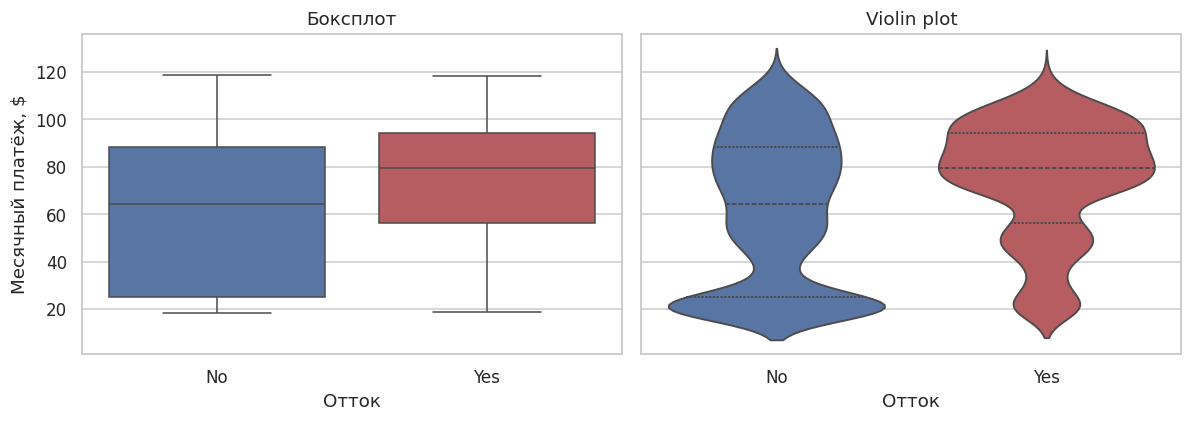

In [90]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", hue="Churn",
            palette=CHURN_COLORS, legend=False, ax=left)
left.set_title("Боксплот")
left.set_xlabel("Отток")
left.set_ylabel("Месячный платёж, $")

sns.violinplot(data=df, x="Churn", y="MonthlyCharges", hue="Churn",
               palette=CHURN_COLORS, legend=False, inner="quartile", ax=right)
right.set_title("Violin plot")
right.set_xlabel("Отток")
right.set_ylabel("")

plt.tight_layout()
plt.show()

Сравнение говорит само за себя. Боксплоты отличаются медианой (у ушедших платёж выше),
но выглядят похоже по форме. Violin plot показывает то, что боксплот скрыл: у оставшихся
клиентов распределение **двугорбое** — отдельная плотная группа дешёвых тарифов около
20 \$ и вторая группа в районе 80 \$. У ушедших нижний горб заметно меньше, а основная
масса собрана в дорогой части. Вывод: клиенты на минимальном тарифе уходят намного реже,
и именно это различие боксплот скрыл.

Те же два графика в plotly. `points="outliers"` оставляет только выбросы (при
`points="all"` на 7 тысячах наблюдений график становится нечитаемым), а `box=True`
у violin вкладывает боксплот внутрь скрипки.

In [91]:
fig = px.box(
    df,
    x="Contract",
    y="MonthlyCharges",
    color="Churn",
    color_discrete_map=CHURN_COLORS,
    points="outliers",
    title="Месячный платёж по типу договора и оттоку (plotly, боксплот)",
    labels={"Contract": "Договор", "MonthlyCharges": "Месячный платёж, $", "Churn": "Отток"},
)

fig.update_layout(width=900, height=430, boxmode="group", legend_title_text="Отток")
fig.show()

In [92]:
fig = px.violin(
    df,
    x="Contract",
    y="MonthlyCharges",
    color="Churn",
    color_discrete_map=CHURN_COLORS,
    box=True,
    points=False,
    title="Месячный платёж по типу договора и оттоку (plotly, violin plot)",
    labels={"Contract": "Договор", "MonthlyCharges": "Месячный платёж, $", "Churn": "Отток"},
)

fig.update_layout(width=900, height=430, violinmode="group", legend_title_text="Отток")
fig.show()

## 8. Тепловая карта: тип интернета × тип договора

Когда нужно сравнить показатель сразу по двум категориальным разрезам, таблица из
двух измерений превращается в тепловую карту: значение кодируется цветом, и аномальные
клетки видно мгновенно.

Строим сводную таблицу `pivot_table` дважды: сначала количество клиентов в каждой
комбинации, затем долю оттока в ней. Обе величины нужны вместе: доля 100 %, посчитанная
по трём клиентам, ничего не значит — ровно та ошибка из вступительного примера лекции
про круговую диаграмму «50/50» без указания размера выборки.

In [93]:

table_size = pd.crosstab(
    df["PaymentMethod"],
    df["Contract"]
)


table_churn = (
    df.pivot_table(
        index="PaymentMethod",
        columns="Contract",
        values="ChurnFlag",
        aggfunc="mean"
    ) * 100
).round(1)

print("Количество клиентов:")
display(table_size)

print("Процент оттока:")
display(table_churn)

small_groups = (
    df.groupby(["PaymentMethod", "Contract"])
      .agg(Количество=("customerID", "count"),
           Отток=("ChurnFlag", "mean"))
      .reset_index()
)

small_groups["Отток"] = (small_groups["Отток"] * 100).round(1)

display(small_groups[small_groups["Количество"] < 50])

Количество клиентов:


Contract,Month-to-month,One year,Two year
PaymentMethod,,,
Bank transfer (automatic),589,391,564
Credit card (automatic),543,398,581
Electronic check,1850,347,168
Mailed check,893,337,382


Процент оттока:


Contract,Month-to-month,One year,Two year
PaymentMethod,,,
Bank transfer (automatic),34.1,9.7,3.4
Credit card (automatic),32.8,10.3,2.2
Electronic check,53.7,18.4,7.7
Mailed check,31.6,6.8,0.8


,PaymentMethod,Contract,Количество,Отток


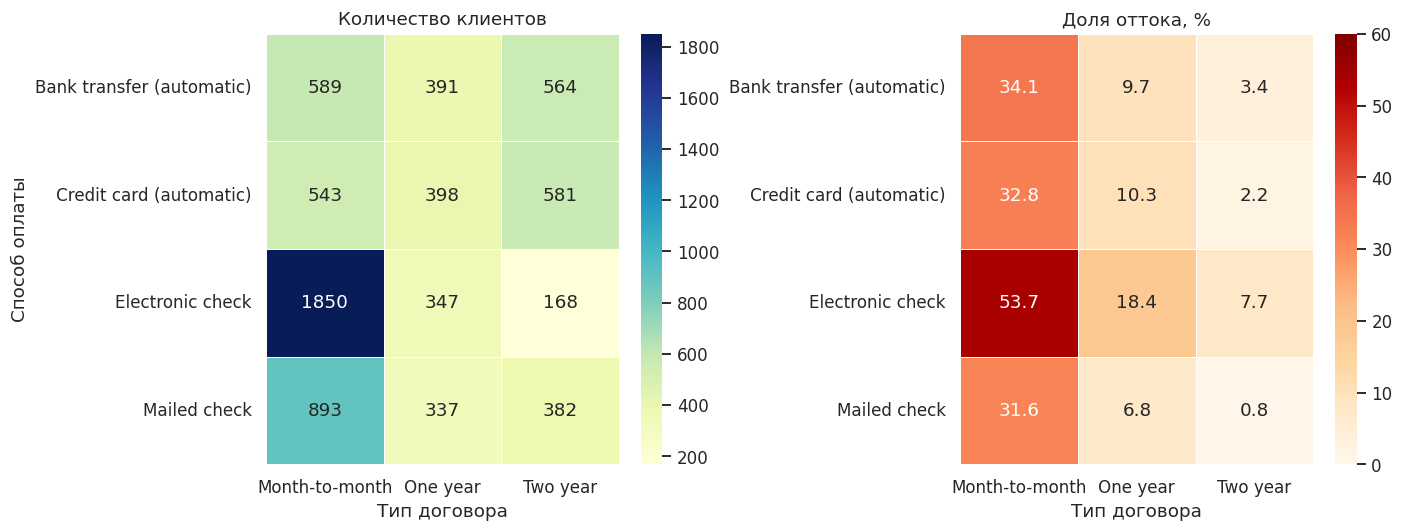

In [94]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(
    table_size,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5,
    ax=ax[0]
)

ax[0].set_title("Количество клиентов")
ax[0].set_xlabel("Тип договора")
ax[0].set_ylabel("Способ оплаты")

sns.heatmap(
    table_churn,
    annot=True,
    fmt=".1f",
    cmap="OrRd",
    vmin=0,
    vmax=60,
    linewidths=0.5,
    ax=ax[1]
)

ax[1].set_title("Доля оттока, %")
ax[1].set_xlabel("Тип договора")
ax[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [95]:
fig = px.imshow(
    table_churn,
    text_auto=".1f",
    color_continuous_scale="YlOrRd",
    zmin=0,
    zmax=60,
    aspect="auto",
    title="Отток клиентов в зависимости от оплаты и договора",
    labels={
        "x": "Тип договора",
        "y": "Способ оплаты",
        "color": "Отток, %"
    }
)

fig.update_layout(width=850, height=450)
fig.show()

Самая проблемная клетка — оптика (`Fiber optic`) на месячном договоре: отток около 55 %
при более чем двух тысячах клиентов, то есть на большой и значимой группе. Для сравнения,
та же оптика на двухлетнем договоре теряет около 7 %. Клиенты без интернета уходят реже
всех при любом типе договора.

Ради этого визуализацию и строят: два разреза, одна картинка — и точка приложения
усилий продукта определена.

## 9. Итоги

**Про инструменты.** Все графики в ноутбуке строились по одной схеме: данные,
оси, разбивка по категории, оформление. Разница в акцентах:

* `matplotlib` — когда нужен полный контроль (как в разделе 5 с двумя панелями и общей осью X);
* `seaborn` — когда нужно быстро посмотреть распределение или разбивку в разведочном анализе;
* `plotly` — когда график смотрит не только автор: интерактивность заменяет десяток
  статичных картинок с разным зумом.

**Про метод.** Порядок действий тот же, что в лекции: сначала формулируется вопрос
и выбирается вид сравнения, и только потом — тип графика. Каждый график в ноутбуке
отвечал на конкретный вопрос, а не украшал отчёт.

**Приёмы, которые сработали на реальных данных:**

| Приём | Где в ноутбуке | Что дал |
|---|---|---|
| Ось от нуля | раздел 4, `range_x=[0, 50]` | различия не преувеличены |
| Нормировка групп разного размера | раздел 3, `common_norm=False` | формы распределений стало можно сравнить |
| Два графика с общей осью X | раздел 5 | видно, на каком объёме посчитана каждая доля |
| Violin вместо боксплота | раздел 7 | обнаружено двугорбое распределение |
| Количество рядом с долей | раздел 8 | доли не интерпретируются по трём наблюдениям |

**Содержательный вывод по данным.** Отток концентрируется в первые месяцы обслуживания,
у клиентов на месячном договоре, с оптикой и оплатой электронным чеком. Это связанные
признаки одного профиля «новый клиент без обязательств», и работать с ним нужно как с целым.

## Задание для самостоятельной работы

1. Постройте распределение `TotalCharges` в трёх библиотеках и объясните, почему оно
   выглядит иначе, чем распределение `MonthlyCharges`.
2. Замените в разделе 8 разрез на `PaymentMethod × Contract`. Появились ли клетки,
   где высокая доля оттока посчитана по слишком маленькой группе?
3. Постройте кривую созревания оттока (раздел 5) отдельно по каждому типу договора —
   три линии на одном графике. Это когортный (винтажный) график из лекции.
4. Выберите любой график из ноутбука и испортите его намеренно: обрежьте ось, уберите
   подписи, поставьте кричащую палитру. Сформулируйте, какой неверный вывод сделает
   читатель по испорченной версии.

In [96]:

bad_data = (
    df.groupby("PaymentMethod", as_index=False)
      .agg(churn_percent=("ChurnFlag", "mean"))
)

bad_data["churn_percent"] *= 100
bad_data = bad_data.sort_values("churn_percent")


fig = px.bar(
    bad_data,
    x="churn_percent",
    y="PaymentMethod",
    orientation="h",
    color="PaymentMethod",
    color_discrete_sequence=[
        "#FF00FF",
        "#00FFFF",
        "#FFFF00",
        "#FF4500"
    ],
    range_x=[10, 50],
    title="Доля оттока по способам оплаты"
)


fig.update_layout(
    title=None,
    xaxis_title=None,
    yaxis_title=None,
    showlegend=False,
    width=900,
    height=420,
    plot_bgcolor="#FFF000",
    paper_bgcolor="#FFB6C1"
)

fig.update_xaxes(
    showticklabels=False,
    showgrid=False,
    zeroline=False
)

fig.update_yaxes(
    showticklabels=False,
    showgrid=False
)


fig.update_traces(hoverinfo="skip")

fig.show()